# Instalar mi paquete

In [ ]:
%pip install -q "git+https://github.com/adbaldel/Complex-Dynamics-Thesis.git#subdirectory=code"

In [ ]:
%pip install -q --upgrade "IPython>=9.17" "pyvista>=0.48.4"

# La familia cuadrática $f_c(z)=z^2+c$

Este cuaderno separa dos planos que conviene no confundir:

- en el **plano de parámetros**, cada píxel representa un valor de $c$ y se itera el punto crítico $z_0=0$;
- en el **plano dinámico**, se fija $c$ y cada píxel representa un valor inicial $z_0$.

El objetivo es aproximar el conjunto de Mandelbrot y comparar varios conjuntos de Julia usando la API actual de `complex_dynamics`. Todas las fronteras dibujadas son aproximaciones de tiempo finito, no certificaciones exactas.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

import complex_dynamics.calculator as dcalc
import complex_dynamics.plot as dplot
from complex_dynamics.rational_map import RationalMap


In [ ]:
import pyvista as pv

pv.set_jupyter_backend("html")

## Estructura de la familia

La aplicación $f_c$ tiene grado $2$, un único punto crítico finito, $0$, y dos puntos fijos dados por

$$z^2-z+c=0,\qquad z_\pm=\frac{1\pm\sqrt{1-4c}}{2}.$$

El conjunto de Julia $J(f_c)$ es conexo si y solo si la órbita crítica $(f_c^n(0))$ es acotada. Esta equivalencia es la razón por la que el conjunto de Mandelbrot se define mediante una sola órbita.

In [3]:
def quadratic_map(c: complex) -> RationalMap:
    """Return f_c(z) = z**2 + c (coefficients are in ascending order)."""
    return RationalMap([c, 0, 1], [1])


c = -1
R = quadratic_map(c)
fixed_points = RationalMap([c, -1, 1], [1]).roots(include_infinity=False)
critical_points = R.derivative().roots(include_infinity=False)

print(f"f_c(z) = {R}")
print(f"degree = {R.degree}")
print(f"fixed points = {fixed_points}")
print(f"finite critical points = {critical_points}")


f_c(z) = z^{2} - 1
degree = 2
fixed points = [-0.61803399+0.j  1.61803399+0.j]
finite critical points = [0.+0.j]


## Plano de parámetros: conjunto de Mandelbrot

Para la órbita crítica de $f_c$, si alguna iteración satisface $|z_n|>2$, entonces la órbita escapa a infinito. La desigualdad debe ser estricta: alcanzar exactamente el radio $2$ no basta por sí solo para detener la iteración.

La siguiente función itera todos los parámetros activos de forma vectorizada. El valor `max_iterations` significa «no se observó escape dentro del límite», no una prueba de pertenencia a $M$.

In [4]:
def calculate_mandelbrot_escape_times(
    parameters: np.ndarray, max_iterations: int
) -> np.ndarray:
    """Count iterations until the critical orbit first satisfies |z| > 2."""
    z = np.zeros(parameters.shape, dtype=np.complex128)
    times = np.zeros(parameters.shape, dtype=np.int_)
    active = np.ones(parameters.shape, dtype=bool)

    for _ in range(max_iterations):
        if not active.any():
            break
        z[active] = z[active] ** 2 + parameters[active]
        times[active] += 1
        active &= np.abs(z) <= 2

    return times


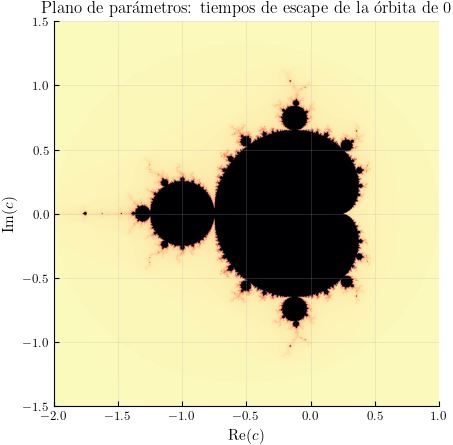

In [5]:
parameter_extent = [-2.0, 1.0, -1.5, 1.5]
parameter_mesh = dcalc.create_mesh(*parameter_extent, xpixels=800, ypixels=800)
max_iterations = 256
parameter_escape_times = calculate_mandelbrot_escape_times(
    parameter_mesh, max_iterations=max_iterations
)

fig, ax = dplot.plot_divergence_times(
    parameter_escape_times,
    max_iterations=max_iterations,
    extent=parameter_extent,
    cmap="magma_r",
)
ax.set_title("Plano de parámetros: tiempos de escape de la órbita de 0")
ax.set_xlabel(r"$\operatorname{Re}(c)$")
ax.set_ylabel(r"$\operatorname{Im}(c)$")
ax.set_aspect("equal")


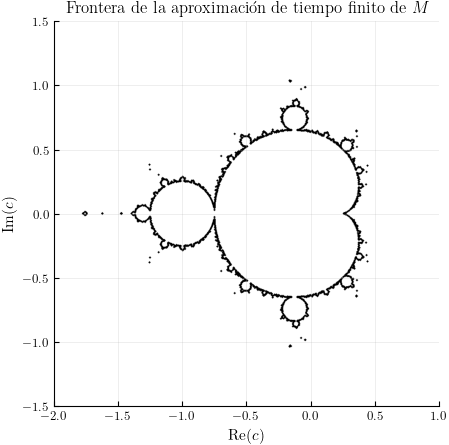

In [6]:
fig, ax = dplot.plot_divergence_times_boundary(
    parameter_escape_times,
    max_iterations=max_iterations,
    thickness=2,
    extent=parameter_extent,
)
ax.set_title("Frontera de la aproximación de tiempo finito de $M$")
ax.set_xlabel(r"$\operatorname{Re}(c)$")
ax.set_ylabel(r"$\operatorname{Im}(c)$")
ax.set_aspect("equal")


## Planos dinámicos

Ahora fijamos $c$. Para $f_c$, el radio

$$r_c=\max(2,|c|)$$

es una cota de escape suficiente una vez que $|z|>r_c$. Como `calculate_divergence_times` usa la convención de primera salida del disco abierto ($|z|\ge r$), empleamos el siguiente número representable después de $r_c$ para respetar la desigualdad estricta.

Los parámetros elegidos muestran dos casos cuya órbita crítica no escapa dentro del límite y dos casos de escape. El dibujo ilustra la equivalencia entre la órbita crítica acotada y la conectividad de $J(f_c)$.

In [7]:
def critical_escape_step(c: complex, max_iterations: int = 512) -> int | None:
    """Return the first n with |f_c**n(0)| > 2, or None within the cap."""
    z = 0j
    for step in range(1, max_iterations + 1):
        z = z**2 + c
        if abs(z) > 2:
            return step
    return None


parameters = [0, -1, -0.123 + 0.745j, 0.5 + 0.5j]
for parameter in parameters:
    step = critical_escape_step(parameter)
    status = (
        f"escapes at n={step}" if step is not None else "no escape observed"
    )
    print(f"c={parameter:>16}: {status}")


c=               0: no escape observed
c=              -1: no escape observed
c= (-0.123+0.745j): no escape observed
c=      (0.5+0.5j): escapes at n=5


Text(0.5, 0.98, 'Planos dinámicos: tiempos de escape')

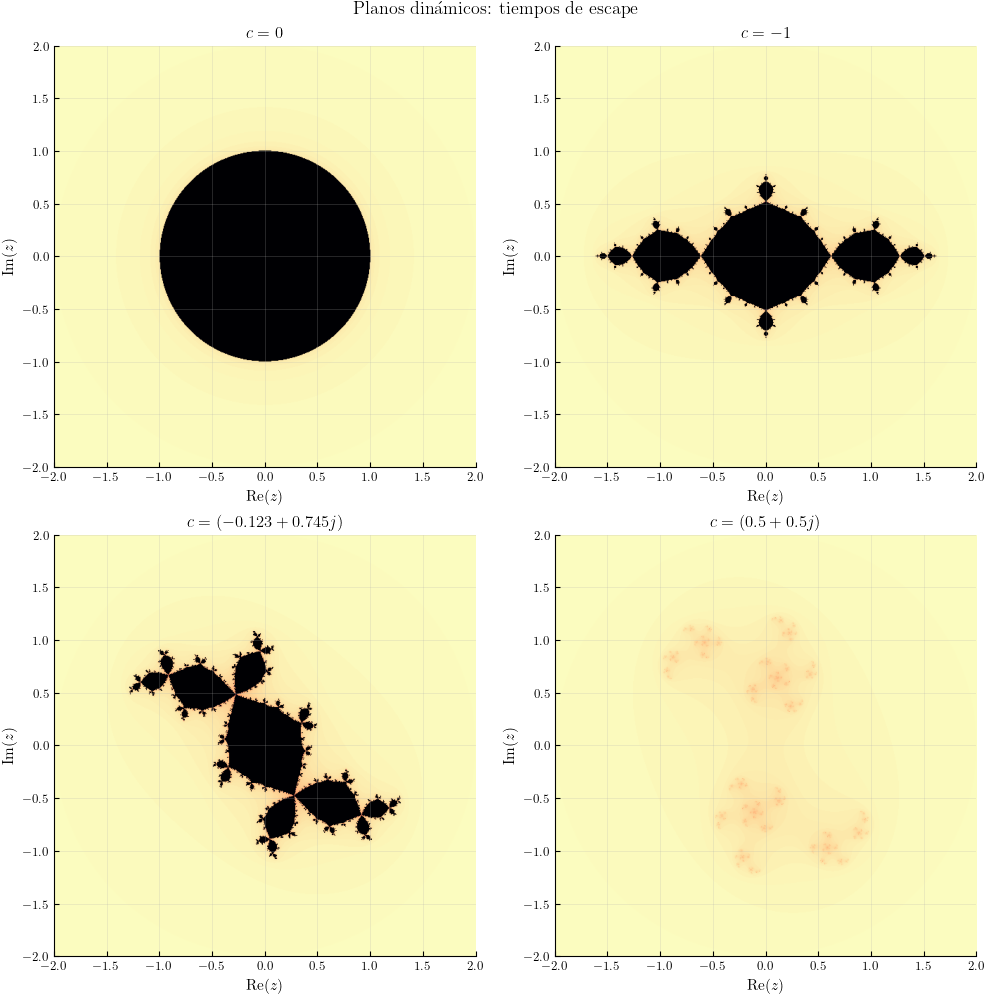

In [8]:
dynamic_extent = [-2.0, 2.0, -2.0, 2.0]
dynamic_mesh = dcalc.create_mesh(*dynamic_extent, xpixels=600, ypixels=600)
max_iterations = 160

fig, axes = plt.subplots(2, 2, figsize=(10, 10), constrained_layout=True)
for ax, parameter in zip(axes.flat, parameters, strict=True):
    R = quadratic_map(parameter)
    strict_escape_radius = np.nextafter(max(2.0, abs(parameter)), np.inf)
    escape_times = dcalc.calculate_divergence_times(
        dynamic_mesh,
        R,
        max_iterations=max_iterations,
        escape_radius=strict_escape_radius,
    )
    dplot.plot_divergence_times(
        escape_times,
        max_iterations=max_iterations,
        ax=ax,
        extent=dynamic_extent,
        cmap="magma_r",
    )
    ax.set_title(rf"$c={parameter}$")
    ax.set_xlabel(r"$\operatorname{Re}(z)$")
    ax.set_ylabel(r"$\operatorname{Im}(z)$")
    ax.set_aspect("equal")

fig.suptitle("Planos dinámicos: tiempos de escape")


## Lectura de los resultados

- Para $c=0$, $J(f_c)$ es la circunferencia unidad.
- Para $c=-1$ aparece la «basílica»: la órbita crítica forma el ciclo superatractor $0\mapsto-1\mapsto0$.
- Para $c\approx-0.123+0.745i$ se observa un Julia conexo asociado a una componente hiperbólica de período $3$.
- Para $c=0.5+0.5i$, la órbita crítica escapa y el Julia es totalmente desconectado.

Los píxeles con cuenta máxima solo indican que no escaparon durante `max_iterations`. Aumentar la resolución y el límite mejora la imagen, pero no convierte el cálculo en una prueba matemática.